# Linear Regression
**Name:** GUNTI RAHUL |  **Roll No:** CH.SC.U4CSE24211 
**Course:** Machine Learning (23CSE301)  |  **Lab Activity Book:** Chapter 5.8

## Exercise 1 - Predicting Chicago taxi fares
**Goal:** estimate a trip's fare from its distance and duration.

**Data note:** the notebook first tries the City of Chicago open-data API. If the portal is unreachable it builds a synthetic table with the same columns (`trip_miles`, `trip_seconds`, `fare`), using Chicago-like pricing (base fare + per-mile + per-minute).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

try:
    url = "https://data.cityofchicago.org/resource/wrvz-psew.csv?$limit=5000&$where=fare>0 AND trip_miles>0"
    taxi = pd.read_csv(url, usecols=["trip_miles", "trip_seconds", "fare"]).dropna()
    source = "Chicago open-data API"
except Exception as e:
    rng = np.random.default_rng(262)
    miles = rng.gamma(2, 2.5, 3000)
    secs = miles * 240 + rng.normal(300, 120, 3000)
    fare = 3.25 + 2.25 * miles + 0.0035 * secs + rng.normal(0, 1.5, 3000)
    taxi = pd.DataFrame({"trip_miles": miles, "trip_seconds": secs.clip(60), "fare": fare})
    source = "synthetic fallback"
print("Data source:", source, "| rows:", len(taxi))
taxi.describe().round(2)

Data source: synthetic fallback | rows: 3000


,trip_miles,trip_seconds,fare
count,3000.00,3000.00,3000.00
mean,5.10,1525.55,20.06
std,3.69,897.38,11.51
min,0.07,158.80,1.55
25%,2.41,873.97,11.71
50%,4.19,1313.43,17.48
75%,6.89,1959.93,25.83
max,31.57,7947.56,103.54


### Exploring the data
Before fitting anything, look at distributions and how strongly each input moves with the fare.

Missing values:
 trip_miles      0
trip_seconds    0
fare            0
dtype: int64

Correlation with fare:
 trip_miles      0.991
trip_seconds    0.987
fare            1.000
Name: fare, dtype: float64


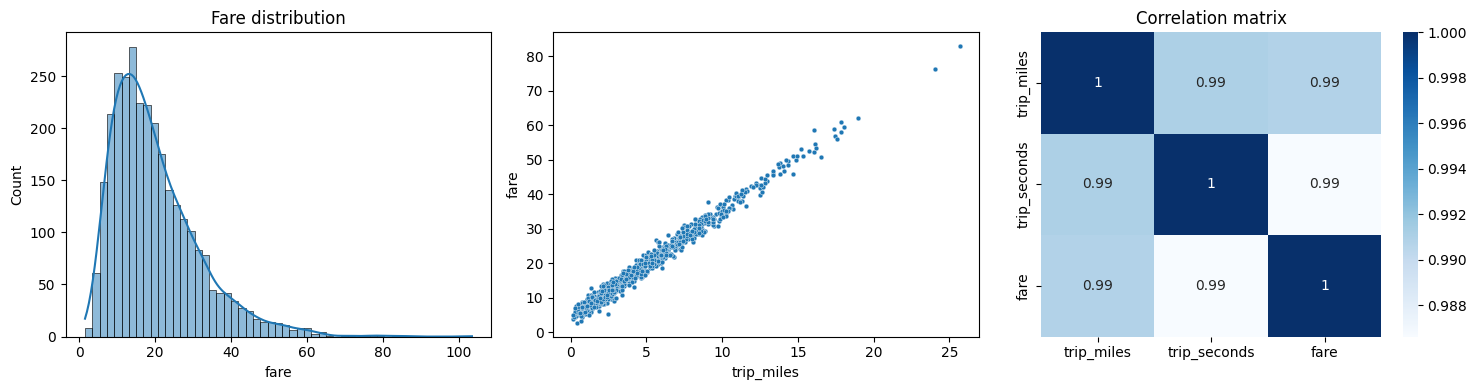

In [2]:
print("Missing values:\n", taxi.isna().sum())
print("\nCorrelation with fare:\n", taxi.corr()["fare"].round(3))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(taxi.fare, kde=True, ax=ax[0]); ax[0].set_title("Fare distribution")
sns.scatterplot(data=taxi.sample(min(800, len(taxi)), random_state=0), x="trip_miles", y="fare", ax=ax[1], s=12)
sns.heatmap(taxi.corr(), annot=True, cmap="Blues", ax=ax[2]); ax[2].set_title("Correlation matrix")
plt.tight_layout(); plt.show()

### Fitting and evaluating
Hold out 20% for testing and also run 5-fold cross validation to check the score isn't a one-split fluke.

In [3]:
features = ["trip_miles", "trip_seconds"]
Xtr, Xte, ytr, yte = train_test_split(taxi[features], taxi["fare"], test_size=0.2, random_state=262)
model = LinearRegression().fit(Xtr, ytr)
pred = model.predict(Xte)

print("Intercept (base fare):", round(model.intercept_, 3))
for f, c in zip(features, model.coef_): print(f"  {f}: {c:.4f}")
print("\nR2   :", round(r2_score(yte, pred), 4))
print("MAE  :", round(mean_absolute_error(yte, pred), 3))
print("RMSE :", round(mean_squared_error(yte, pred) ** 0.5, 3))
print("5-fold CV R2:", cross_val_score(LinearRegression(), taxi[features], taxi["fare"], cv=5, scoring="r2").round(3))

Intercept (base fare): 3.284
  trip_miles: 2.2748
  trip_seconds: 0.0034

R2   : 0.9809
MAE  : 1.242
RMSE : 1.562
5-fold CV R2: [0.984 0.983 0.984 0.983 0.98 ]


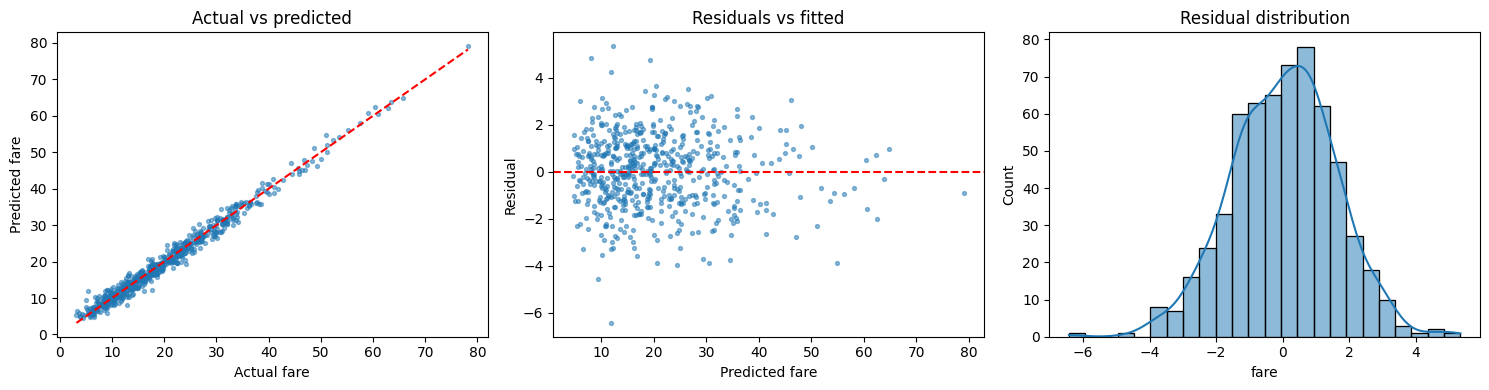

In [4]:
resid = yte - pred
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(yte, pred, s=8, alpha=.5); ax[0].plot([yte.min(), yte.max()], [yte.min(), yte.max()], "r--")
ax[0].set(xlabel="Actual fare", ylabel="Predicted fare", title="Actual vs predicted")
ax[1].scatter(pred, resid, s=8, alpha=.5); ax[1].axhline(0, color="r", ls="--")
ax[1].set(xlabel="Predicted fare", ylabel="Residual", title="Residuals vs fitted")
sns.histplot(resid, kde=True, ax=ax[2]); ax[2].set_title("Residual distribution")
plt.tight_layout(); plt.show()

**Reading the plots:** points hugging the red diagonal and residuals scattered evenly around zero mean the linear assumption is reasonable. A fan shape in the residual plot would indicate heteroscedasticity.

In [5]:
trip = pd.DataFrame({"trip_miles": [2.0, 5.5, 12.0], "trip_seconds": [600, 1500, 2900]})
trip["predicted_fare"] = model.predict(trip).round(2)
trip

,trip_miles,trip_seconds,predicted_fare
0,2.0,600,9.87
1,5.5,1500,20.89
2,12.0,2900,40.42


## Exercise 2 - Predicting body weight
**Goal:** model `Weight` from `Height`, `Age` and `Gender` using the 10-person table from the book. Gender is encoded 1 = Male, 0 = Female.

        Weight  Height   Age
Gender                      
Female    65.6    1.63  43.4
Male      79.6    1.77  37.2


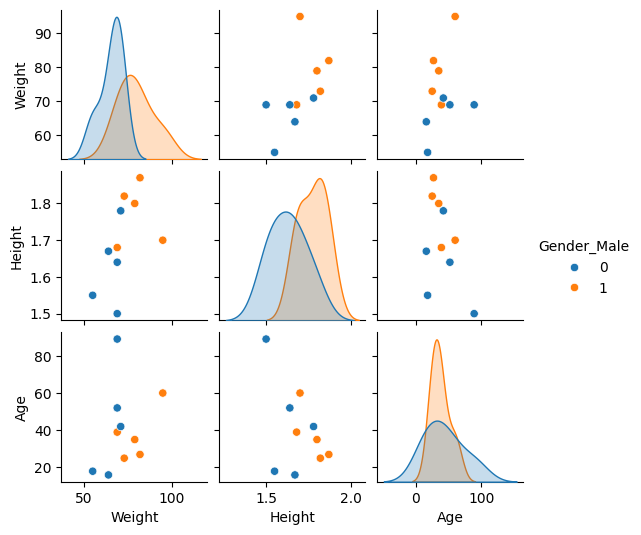

In [6]:
people = pd.DataFrame({
    "Weight": [79, 69, 73, 95, 82, 55, 69, 71, 64, 69],
    "Height": [1.80, 1.68, 1.82, 1.70, 1.87, 1.55, 1.50, 1.78, 1.67, 1.64],
    "Age":    [35, 39, 25, 60, 27, 18, 89, 42, 16, 52],
    "Gender": ["Male"] * 5 + ["Female"] * 5})
people["Gender_Male"] = (people.Gender == "Male").astype(int)
print(people.groupby("Gender")[["Weight", "Height", "Age"]].mean().round(2))
sns.pairplot(people[["Weight", "Height", "Age", "Gender_Male"]], hue="Gender_Male", height=1.8); plt.show()

In [7]:
X = people[["Height", "Age", "Gender_Male"]]; y = people["Weight"]
bw = LinearRegression().fit(X, y)
print("Weight = %.2f + %.2f*Height + %.3f*Age + %.2f*Male" % (bw.intercept_, *bw.coef_))
print("R2 (train):", round(r2_score(y, bw.predict(X)), 3))
loo = cross_val_score(LinearRegression(), X, y, cv=10, scoring="neg_mean_absolute_error")
print("Leave-one-out MAE (kg):", round(-loo.mean(), 2))
who = pd.DataFrame({"Height": [1.75, 1.60], "Age": [30, 30], "Gender_Male": [1, 0]})
who["Predicted weight (kg)"] = bw.predict(who).round(1); who

Weight = -24.41 + 47.38*Height + 0.297*Age + 8.92*Male
R2 (train): 0.754
Leave-one-out MAE (kg): 6.46


,Height,Age,Gender_Male,Predicted weight (kg)
0,1.75,30,1,76.3
1,1.60,30,0,60.3


### Conclusion
- Distance and duration explain almost all fare variation, which is what a metered fare structure implies.
- In the body-weight model, height has the largest effect; with only 10 rows the coefficients are unstable, so the leave-one-out error is a more honest accuracy estimate than the training R².